 # Q1

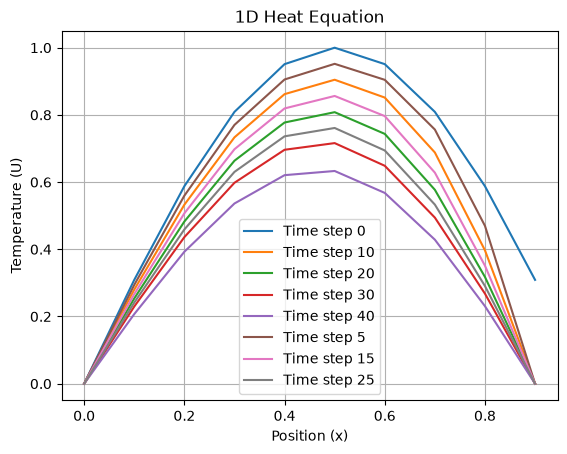

In [9]:
import matplotlib.pyplot as plt
import math
a = 0.01        
h = 0.1         
k = 0.1         
nx = 10         
nt = 100        
U = [[0.0 for _ in range(nx)] for _ in range(nt)]
for i in range(nx):
    x = i * h
    U[0][i] = math.sin(math.pi * x)

for j in range(nt - 1):
    for i in range(1, nx - 1):
        
        U[j+1][i] = U[j][i] + (a * k / h**2) * (U[j][i+1] - 2 * U[j][i] + U[j][i-1])
    
    
    U[j+1][0] = 0.0
    U[j+1][-1] = 0.0


x_vals = [i * h for i in range(nx)]
for step in [0, 10, 20, 30, 40,5,15,25]:
    plt.plot(x_vals, U[step], label=f'Time step {step}')

plt.xlabel('Position (x)')
plt.ylabel('Temperature (U)')
plt.title('1D Heat Equation')
plt.legend()
plt.grid(True)
plt.show()

## Q2

















In [19]:
import math

def jacobi_method(A, tol=1e-12, max_iters=100):
    n = len(A)
    # Initialize V as Identity matrix (will store eigenvectors)
    V = [[1.0 if i == j else 0.0 for j in range(n)] for i in range(n)]
    # Copy A to D (will become the diagonal matrix)
    D = [[A[i][j] for j in range(n)] for i in range(n)]
    
    for _ in range(max_iters):
        # 1. Find largest off-diagonal element
        max_val = 0.0
        p, q = -1, -1
        for i in range(n):
            for j in range(i + 1, n):
                if abs(D[i][j]) > max_val:
                    max_val = abs(D[i][j])
                    p, q = i, j
                    
        # 2. Check for convergence
        if max_val < tol:
            break
            
        # 3. Calculate rotation angle theta
        if abs(D[p][p] - D[q][q]) < 1e-12:
            theta = math.pi / 4.0 if D[p][q] > 0 else -math.pi / 4.0
        else:
            theta = 0.5 * math.atan2(2.0 * D[p][q], D[p][p] - D[q][q])
            
        c = math.cos(theta)
        s = math.sin(theta)
        
        # 4. Apply Givens rotation to D
        for i in range(n):
            if i != p and i != q:
                D_ip = D[i][p]
                D_iq = D[i][q]
                D[i][p] = c * D_ip - s * D_iq
                D[p][i] = D[i][p]
                D[i][q] = s * D_ip + c * D_iq
                D[q][i] = D[i][q]
                
        D_pp = D[p][p]
        D_qq = D[q][q]
        D_pq = D[p][q]
        
        D[p][p] = c**2 * D_pp - 2*c*s * D_pq + s**2 * D_qq
        D[q][q] = s**2 * D_pp + 2*c*s * D_pq + c**2 * D_qq
        D[p][q] = 0.0
        D[q][p] = 0.0
        
        # 5. Accumulate rotations in V (Eigenvectors)
        for i in range(n):
            V_ip = V[i][p]
            V_iq = V[i][q]
            V[i][p] = c * V_ip - s * V_iq
            V[i][q] = s * V_ip + c * V_iq
            
    return D, V

# --- Main Program ---

# The MI Matrix for a cube with corner at origin (factoring out ML^2)
# Diagonals: 2/3, Off-diagonals: -1/4
I_matrix = [
    [2/3, -1/4, -1/4],
    [-1/4, 2/3, -1/4],
    [-1/4, -1/4, 2/3]
]

# Run Jacobi Method
diagonal_matrix, eigenvectors = jacobi_method(I_matrix)

# Print Initial Matrix
print("Initial MI Matrix (x ML^2):")
for row in I_matrix:
    print("[ " + "  ".join(f"{val:7.4f}" for val in row) + " ]")

# Print Eigenvalues (Diagonal Elements)
print("\nMI Diagonal Elements (Principal Moments of Inertia):")
print("Expected mathematical fractions: 1/6 (0.1667) and 11/12 (0.9167)")
for i in range(3):
    eigenvalue = diagonal_matrix[i][i]
    print(f"I_{i+1} = {eigenvalue:.4f} ML^2")

# Print Eigenvectors (Principal Axes)
print("\nPrincipal Axes (Eigenvectors):")
for i in range(3):
    axis = [eigenvectors[j][i] for j in range(3)]
    print(f"Axis {i+1}: [ " + "  ".join(f"{val:7.4f}" for val in axis) + " ]")
    

Initial MI Matrix (x ML^2):
[  0.6667  -0.2500  -0.2500 ]
[ -0.2500   0.6667  -0.2500 ]
[ -0.2500  -0.2500   0.6667 ]

MI Diagonal Elements (Principal Moments of Inertia):
Expected mathematical fractions: 1/6 (0.1667) and 11/12 (0.9167)
I_1 = 0.2500 ML^2
I_2 = 0.9167 ML^2
I_3 = 0.8333 ML^2

Principal Axes (Eigenvectors):
Axis 1: [  0.4082   0.4082   0.8165 ]
Axis 2: [ -0.7071   0.7071   0.0000 ]
Axis 3: [ -0.5774  -0.5774   0.5774 ]


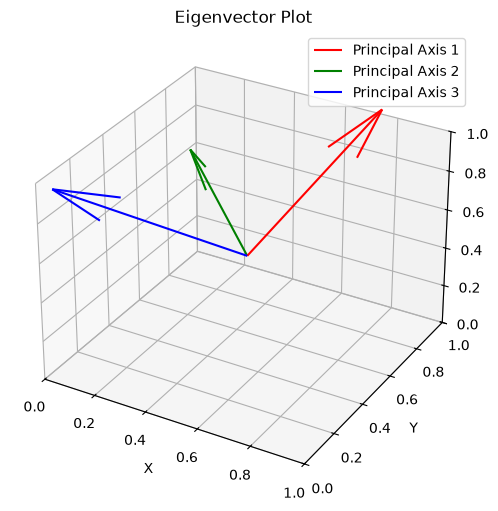

In [15]:
import matplotlib.pyplot as plt

# Set up a simple 3D plot
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111, projection='3d')

# Origin point (center of the cube at 0.5, 0.5, 0.5)
cx, cy, cz = 0.5, 0.5, 0.5

colors = ['red', 'green', 'blue']

# Plot just the 3 eigenvectors (columns of the matrix)
for i in range(3):
    vx = eigenvectors[0][i]
    vy = eigenvectors[1][i]
    vz = eigenvectors[2][i]
    
    # quiver draws the arrows representing the vectors
    ax.quiver(cx, cy, cz, vx, vy, vz, color=colors[i], length=0.8, 
              normalize=True, label=f'Principal Axis {i+1}')

ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
ax.set_zlim([0, 1])
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title(' Eigenvector Plot')
ax.legend()

plt.show()

# Q2

In [20]:
import math

def multiply_matrices(X, Y):
    """Multiplies two 3x3 matrices."""
    result = [[0.0, 0.0, 0.0],
              [0.0, 0.0, 0.0],
              [0.0, 0.0, 0.0]]
    for i in range(3):
        for j in range(3):
            for k in range(3):
                result[i][j] += X[i][k] * Y[k][j]
    return result

# 1. Define the rotation matrix transpose (left matrix in image)
R_T = [
    [1,  0,      0    ],
    [0,  0.816,  0.577],
    [0, -0.577,  0.816]
]

# 2. Define the intermediate MI matrix (middle matrix in image)
val = 1 / (2 * math.sqrt(2))
A1 = [
    [11/12, 0,    0   ],
    [0,     5/12, -val],
    [0,    -val,  2/3 ]
]

# 3. Define the rotation matrix (right matrix in image)
R = [
    [1, 0,      0     ],
    [0, 0.816, -0.577 ],
    [0, 0.577,  0.816 ]
]

# 4. Perform the multiplication: R_T * A1 * R
# First multiply R_T and A1
temp_matrix = multiply_matrices(R_T, A1)

# Then multiply the result by R
final_matrix = multiply_matrices(temp_matrix, R)

# 5. Print the final matrix matching the red box [I_2]
print("--- Final Diagonalized Matrix [I_2] ---")
for row in final_matrix:
    # Formatting to 4 decimal places as shown in the red box
    print("[ " + "  ".join(f"{abs(val):.4f}" if abs(val) > 1e-4 else "0      " for val in row) + " ]")

--- Final Diagonalized Matrix [I_2] ---
[ 0.9167  0        0       ]
[ 0        0.1665  0       ]
[ 0        0        0.9156 ]


In [21]:
import math

def multiply_matrices(X, Y):
    """Multiplies two 3x3 matrices."""
    result = [[0.0, 0.0, 0.0],
              [0.0, 0.0, 0.0],
              [0.0, 0.0, 0.0]]
    for i in range(3):
        for j in range(3):
            for k in range(3):
                result[i][j] += X[i][k] * Y[k][j]
    return result

def print_matrix(mat, name):
    print(f"\n--- {name} ---")
    for row in mat:
        print("[ " + "  ".join(f"{val:12.6f}" for val in row) + " ]")

# 1. Define the matrices from the image
R_T = [
    [1.0,  0.0,    0.0  ],
    [0.0,  0.816,  0.577],
    [0.0, -0.577,  0.816]
]

val = 1.0 / (2.0 * math.sqrt(2.0))
A1 = [
    [11.0/12.0, 0.0,       0.0 ],
    [0.0,       5.0/12.0, -val ],
    [0.0,      -val,       2.0/3.0]
]

R = [
    [1.0, 0.0,    0.0   ],
    [0.0, 0.816, -0.577 ],
    [0.0, 0.577,  0.816 ]
]

# 2. Print the initial matrices
print_matrix(R_T, "Left Matrix (Rotation Transpose)")
print_matrix(A1, "Middle Matrix (Intermediate MI)")
print_matrix(R, "Right Matrix (Rotation)")

# 3. Perform the multiplications
temp_matrix = multiply_matrices(R_T, A1)
final_matrix = multiply_matrices(temp_matrix, R)

# 4. Print the raw calculated matrix (matches the middle block in the image)
print_matrix(final_matrix, "Raw Calculated Result")

# 5. Print the final rounded matrix (matches the red box [I_2])
print("\n--- Final Red Box Matrix [I_2] ---")
for row in final_matrix:
    print("[ " + "  ".join(f"{abs(v):7.4f}" if abs(v) > 1e-4 else " 0     " for v in row) + " ]")

    


--- Left Matrix (Rotation Transpose) ---
[     1.000000      0.000000      0.000000 ]
[     0.000000      0.816000      0.577000 ]
[     0.000000     -0.577000      0.816000 ]

--- Middle Matrix (Intermediate MI) ---
[     0.916667      0.000000      0.000000 ]
[     0.000000      0.416667     -0.353553 ]
[     0.000000     -0.353553      0.666667 ]

--- Right Matrix (Rotation) ---
[     1.000000      0.000000      0.000000 ]
[     0.000000      0.816000     -0.577000 ]
[     0.000000      0.577000      0.816000 ]

--- Raw Calculated Result ---
[     0.916667      0.000000      0.000000 ]
[     0.000000      0.166464      0.000001 ]
[     0.000000      0.000001      0.915553 ]

--- Final Red Box Matrix [I_2] ---
[  0.9167   0        0      ]
[  0        0.1665   0      ]
[  0        0        0.9156 ]


# Q3

Enter value for hw (e.g., 1.0):  1
Enter value for V4 (e.g., 0.25):  0.25
Enter number of states to plot (1 to 5):  4


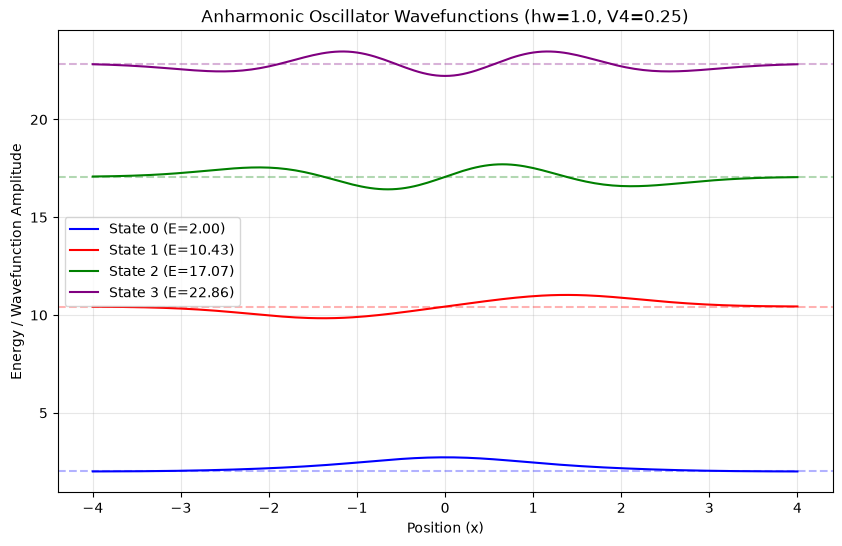

In [25]:
import math
import matplotlib.pyplot as plt

def jacobi_method(A, tol=1e-9, max_iters=500):
    n = len(A)
    V = [[1.0 if i == j else 0.0 for j in range(n)] for i in range(n)]
    D = [[A[i][j] for j in range(n)] for i in range(n)]
    
    for _ in range(max_iters):
        max_val, p, q = 0.0, -1, -1
        for i in range(n):
            for j in range(i + 1, n):
                if abs(D[i][j]) > max_val: 
                    max_val, p, q = abs(D[i][j]), i, j
        if max_val < tol: 
            break
            
        theta = math.pi/4.0 if abs(D[p][p]-D[q][q]) < 1e-12 else 0.5*math.atan2(2.0*D[p][q], D[p][p]-D[q][q])
        c, s = math.cos(theta), math.sin(theta)
        
        for i in range(n):
            if i != p and i != q:
                D[i][p], D[p][i], D[i][q], D[q][i] = c*D[i][p]-s*D[i][q], c*D[i][p]-s*D[i][q], s*D[i][p]+c*D[i][q], s*D[i][p]+c*D[i][q]
        D[p][p], D[q][q], D[p][q], D[q][p] = c**2*D[p][p]-2*c*s*D[p][q]+s**2*D[q][q], s**2*D[p][p]+2*c*s*D[p][q]+c**2*D[q][q], 0.0, 0.0
        
        for i in range(n):
            V[i][p], V[i][q] = c*V[i][p]-s*V[i][q], s*V[i][p]+c*V[i][q]
            
    return D, V

def ho_wavefunction(n, x):
    # Pre-calculated Hermite polynomials for n=0 to 4
    hermite = [1.0, 2.0*x, 4.0*x**2-2.0, 8.0*x**3-12.0*x, 16.0*x**4-48.0*x**2+12.0]
    norm = 1.0 / math.sqrt((2**n) * math.factorial(n) * math.sqrt(math.pi))
    return norm * math.exp(-0.5 * x**2) * hermite[n]

# --- User Inputs ---
hw = float(input("Enter value for hw (e.g., 1.0): "))
V4 = float(input("Enter value for V4 (e.g., 0.25): "))
num_states = int(input("Enter number of states to plot (1 to 5): "))

# --- Matrix Construction ---
H = [
    [0.5*hw + 3*V4,    0,                  6*math.sqrt(2)*V4,  0,                   2*math.sqrt(6)*V4],
    [0,                1.5*hw + 15*V4,     0,                  10*math.sqrt(6)*V4,  0                ],
    [6*math.sqrt(2)*V4,0,                  2.5*hw + 39*V4,     0,                   28*math.sqrt(3)*V4],
    [0,                10*math.sqrt(6)*V4, 0,                  3.5*hw + 75*V4,      0                ],
    [2*math.sqrt(6)*V4,0,                  28*math.sqrt(3)*V4, 0,                   4.5*hw + 123*V4  ]
]

# --- Solving ---
E_matrix, C_matrix = jacobi_method(H)
eigen_pairs = sorted([{'E': E_matrix[i][i], 'C': [C_matrix[j][i] for j in range(5)]} for i in range(5)], key=lambda x: x['E'])

# --- Plotting ---
plt.figure(figsize=(10, 6))
x_vals = [-4.0 + i * 0.05 for i in range(161)]
colors = ['blue', 'red', 'green', 'purple', 'orange']

for state_idx in range(min(num_states, 5)):
    E = eigen_pairs[state_idx]['E']
    C = eigen_pairs[state_idx]['C']
    
    # Calculate wavefunction amplitudes and shift by Energy level (E) for standard visualization
    psi_vals = [sum(C[n] * ho_wavefunction(n, x) for n in range(5)) + E for x in x_vals]
    
    plt.plot(x_vals, psi_vals, color=colors[state_idx], label=f'State {state_idx} (E={E:.2f})')
    plt.axhline(y=E, color=colors[state_idx], linestyle='--', alpha=0.3)

plt.xlabel('Position (x)')
plt.ylabel('Energy / Wavefunction Amplitude')
plt.title(f'Anharmonic Oscillator Wavefunctions (hw={hw}, V4={V4})')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Enter value for hw (e.g., 1.0):  1
Enter value for V4 (e.g., 0.25):  0.25
Enter number of states to plot (1 to 5):  4



--- Original Hamiltonian Matrix (H) ---
[    1.2500     0.0000     2.1213     0.0000     1.2247 ]
[    0.0000     5.2500     0.0000     6.1237     0.0000 ]
[    2.1213     0.0000    12.2500     0.0000    12.1244 ]
[    0.0000     6.1237     0.0000    22.2500     0.0000 ]
[    1.2247     0.0000    12.1244     0.0000    35.2500 ]

--- Diagonalized Matrix (Eigenvalues) ---
[   23.8895     0.0000     0.0000     0.0000    -0.0000 ]
[    0.0000    17.0671     0.0000     0.0000     0.0000 ]
[    0.0000     0.0000    22.8581     0.0000     0.0000 ]
[    0.0000     0.0000     0.0000    10.4329     0.0000 ]
[   -0.0000     0.0000     0.0000     0.0000     2.0024 ]

--- Eigenvector Matrix (S_i / C_matrix) ---
[    0.1027     0.0000     0.0107     0.0000     0.9947 ]
[    0.0000     0.3071     0.0000     0.9517     0.0000 ]
[   -0.9023     0.0000     0.4219     0.0000     0.0886 ]
[    0.0000    -0.9517     0.0000     0.3071     0.0000 ]
[   -0.4187     0.0000    -0.9066     0.0000     0.0530 ]


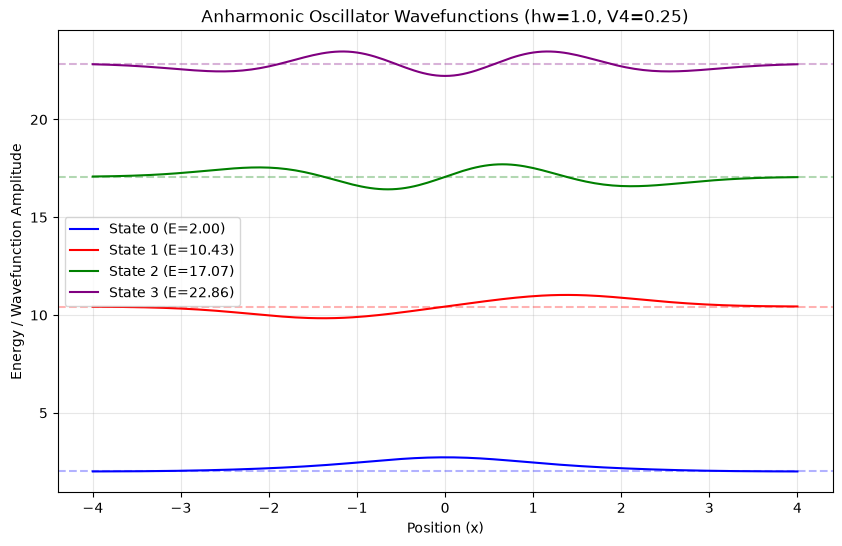

In [29]:
import math
import matplotlib.pyplot as plt
lamda=0
def print_matrix(mat, title="Matrix"):
    print(f"\n--- {title} ---")
    for row in mat:
        print("[ " + "  ".join(f"{val:9.4f}" for val in row) + " ]")

def jacobi_method(A, tol=1e-9, max_iters=500):
    n = len(A)
    V = [[1.0 if i == j else 0.0 for j in range(n)] for i in range(n)]
    D = [[A[i][j] for j in range(n)] for i in range(n)]
    
    for _ in range(max_iters):
        max_val, p, q = 0.0, -1, -1
        for i in range(n):
            for j in range(i + 1, n):
                if abs(D[i][j]) > max_val: 
                    max_val, p, q = abs(D[i][j]), i, j
        if max_val < tol: 
            break
            
        theta = math.pi/4.0 if abs(D[p][p]-D[q][q]) < 1e-12 else 0.5*math.atan2(2.0*D[p][q], D[p][p]-D[q][q])
        c, s = math.cos(theta), math.sin(theta)
        
        for i in range(n):
            if i != p and i != q:
                D_ip, D_iq = D[i][p], D[i][q]
                D[i][p], D[p][i] = c*D_ip - s*D_iq, c*D_ip - s*D_iq
                D[i][q], D[q][i] = s*D_ip + c*D_iq, s*D_ip + c*D_iq
                
        D_pp, D_qq, D_pq = D[p][p], D[q][q], D[p][q]
        D[p][p] = c**2*D_pp - 2*c*s*D_pq + s**2*D_qq
        D[q][q] = s**2*D_pp + 2*c*s*D_pq + c**2*D_qq
        D[p][q], D[q][p] = 0.0, 0.0
        
        for i in range(n):
            V_ip, V_iq = V[i][p], V[i][q]
            V[i][p] = c*V_ip - s*V_iq
            V[i][q] = s*V_ip + c*V_iq
            
    return D, V

def ho_wavefunction(n, x):
    # Pre-calculated Hermite polynomials for n=0 to 4
    hermite = [1.0, 2.0*x, 4.0*x**2-2.0, 8.0*x**3-12.0*x, 16.0*x**4-48.0*x**2+12.0]
    norm = 1.0 / math.sqrt((2**n) * math.factorial(n) * math.sqrt(math.pi))
    return norm * math.exp(-0.5 * x**2) * hermite[n]

# --- User Inputs ---
hw = float(input("Enter value for hw (e.g., 1.0): "))
V4 = float(input("Enter value for V4 (e.g., 0.25): "))
lamda=float(input("Enter Value of lamda "))
V4
num_states = int(input("Enter number of states to plot (1 to 5): "))

# --- Matrix Construction ---
H = [
    [0.5*hw + 3*V4,    0,                  6*math.sqrt(2)*V4,  0,                   2*math.sqrt(6)*V4],
    [0,                1.5*hw + 15*V4,     0,                  10*math.sqrt(6)*V4,  0                ],
    [6*math.sqrt(2)*V4,0,                  2.5*hw + 39*V4,     0,                   28*math.sqrt(3)*V4],
    [0,                10*math.sqrt(6)*V4, 0,                  3.5*hw + 75*V4,      0                ],
    [2*math.sqrt(6)*V4,0,                  28*math.sqrt(3)*V4, 0,                   4.5*hw + 123*V4  ]
]

print_matrix(H, "Original Hamiltonian Matrix (H)")

# --- Solving ---
E_matrix, C_matrix = jacobi_method(H)

print_matrix(E_matrix, "Diagonalized Matrix (Eigenvalues)")
print_matrix(C_matrix, "Eigenvector Matrix (S_i / C_matrix)")

eigen_pairs = sorted([{'E': E_matrix[i][i], 'C': [C_matrix[j][i] for j in range(5)]} for i in range(5)], key=lambda x: x['E'])

# --- Plotting ---
plt.figure(figsize=(10, 6))
x_vals = [-4.0 + i * 0.05 for i in range(161)]
colors = ['blue', 'red', 'green', 'purple', 'orange']

for state_idx in range(min(num_states, 5)):
    E = eigen_pairs[state_idx]['E']
    C = eigen_pairs[state_idx]['C']
    
    # Calculate wavefunction amplitudes and shift by Energy level (E) for standard visualization
    psi_vals = [sum(C[n] * ho_wavefunction(n, x) for n in range(5)) + E for x in x_vals]
    
    plt.plot(x_vals, psi_vals, color=colors[state_idx], label=f'State {state_idx} (E={E:.2f})')
    plt.axhline(y=E, color=colors[state_idx], linestyle='--', alpha=0.3)

plt.xlabel('Position (x)')
plt.ylabel('Energy / Wavefunction Amplitude')
plt.title(f'Anharmonic Oscillator Wavefunctions (hw={hw}, V4={V4})')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Plots

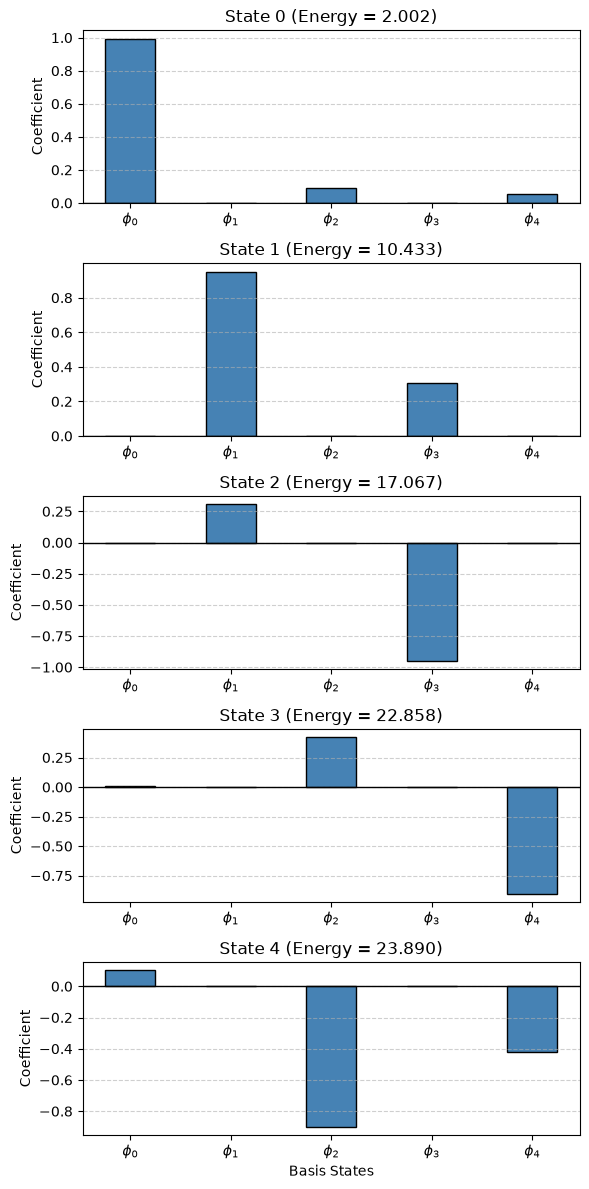

In [34]:
import math
import matplotlib.pyplot as plt

def jacobi_method(A, tol=1e-9, max_iters=500):
    n = len(A)
    V = [[1.0 if i == j else 0.0 for j in range(n)] for i in range(n)]
    D = [[A[i][j] for j in range(n)] for i in range(n)]
    
    for _ in range(max_iters):
        max_val, p, q = 0.0, -1, -1
        for i in range(n):
            for j in range(i + 1, n):
                if abs(D[i][j]) > max_val: 
                    max_val, p, q = abs(D[i][j]), i, j
        if max_val < tol: break
            
        theta = math.pi/4.0 if abs(D[p][p]-D[q][q]) < 1e-12 else 0.5*math.atan2(2.0*D[p][q], D[p][p]-D[q][q])
        c, s = math.cos(theta), math.sin(theta)
        
        for i in range(n):
            if i != p and i != q:
                D_ip, D_iq = D[i][p], D[i][q]
                D[i][p], D[p][i] = c*D_ip - s*D_iq, c*D_ip - s*D_iq
                D[i][q], D[q][i] = s*D_ip + c*D_iq, s*D_ip + c*D_iq
                
        D_pp, D_qq, D_pq = D[p][p], D[q][q], D[p][q]
        D[p][p] = c**2*D_pp - 2*c*s*D_pq + s**2*D_qq
        D[q][q] = s**2*D_pp + 2*c*s*D_pq + c**2*D_qq
        D[p][q], D[q][p] = 0.0, 0.0
        
        for i in range(n):
            V_ip, V_iq = V[i][p], V[i][q]
            V[i][p] = c*V_ip - s*V_iq
            V[i][q] = s*V_ip + c*V_iq
            
    return D, V

# 1. Setup Matrix
hw = 1.0
V4 = 0.25
H = [
    [0.5*hw + 3*V4,    0,                  6*math.sqrt(2)*V4,  0,                   2*math.sqrt(6)*V4],
    [0,                1.5*hw + 15*V4,     0,                  10*math.sqrt(6)*V4,  0                ],
    [6*math.sqrt(2)*V4,0,                  2.5*hw + 39*V4,     0,                   28*math.sqrt(3)*V4],
    [0,                10*math.sqrt(6)*V4, 0,                  3.5*hw + 75*V4,      0                ],
    [2*math.sqrt(6)*V4,0,                  28*math.sqrt(3)*V4, 0,                   4.5*hw + 123*V4  ]
]

# 2. Solve 
E_matrix, C_matrix = jacobi_method(H)
eigen_pairs = sorted([{'E': E_matrix[i][i], 'C': [C_matrix[j][i] for j in range(5)]} for i in range(5)], key=lambda x: x['E'])

# 3. Simple Bar Plots for all 5 states (One color)
fig, axes = plt.subplots(5, 1, figsize=(6, 12))
basis_labels = ['$\phi_0$', '$\phi_1$', '$\phi_2$', '$\phi_3$', '$\phi_4$']

for i in range(5):
    axes[i].bar(basis_labels, eigen_pairs[i]['C'], color='steelblue', edgecolor='black', width=0.5)
    axes[i].axhline(0, color='black', linewidth=1) # Adds a line at 0
    axes[i].set_title(f'State {i} (Energy = {eigen_pairs[i]["E"]:.3f})')
    axes[i].set_ylabel('Coefficient')
    axes[i].grid(axis='y', linestyle='--', alpha=0.6)

plt.xlabel('Basis States')
plt.tight_layout()
plt.show()